# Import Module

In [ ]:
from google.colab import drive
drive.mount('/content/drive') #---

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
!pip install pylr2

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pylr2 import regress2

ModuleNotFoundError: No module named 'pylr2'

# Mempersiapkan Data

In [ ]:
# Data perhitungan Rafi
df = pd.read_csv('Hasil\Perbandingan_data.csv') 
df['timestamp'] = pd.to_datetime(df['timestamp'])

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 354 entries, 0 to 353
Data columns (total 21 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   timestamp                          354 non-null    datetime64[us]
 1   co2_flux                           346 non-null    float64       
 2   C02_flux_processing (μmol/m²/s)    354 non-null    float64       
 3   h2o_mole_fraction                  346 non-null    float64       
 4   H2O Mole Fraction (mmol/mol_a)     354 non-null    float64       
 5   h2o_mixing_ratio                   346 non-null    float64       
 6   H2O Mixing Ratio (mmol/mol_d)      354 non-null    float64       
 7   air_density                        346 non-null    float64       
 8   Mass Density of Air (kg/m^3)       354 non-null    float64       
 9   air_molar_volume                   346 non-null    float64       
 10  Molar Volume of Air (m^3/mol)      354 non-null  

<>:2: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:2: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
C:\Users\lenovo\AppData\Local\Temp\ipykernel_20272\626995708.py:2: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
  df = pd.read_csv('Hasil\Perbandingan_data.csv')


In [17]:
df.head()

,co2_flux,C02_flux_processing (μmol/m²/s),h2o_mole_fraction,H2O Mole Fraction (mmol/mol_a),h2o_mixing_ratio,H2O Mixing Ratio (mmol/mol_d),air_density,Mass Density of Air (kg/m^3),air_molar_volume,Molar Volume of Air (m^3/mol),e,Water Vapor Partial Pressure (Pa),es,Saturation Vapor Pressure (Pa),Tdew,Dew point temperature (K),co2_mixing_ratio,CO2 Mixing Ratio (µmol/mol_d),w_unrot,w (m/s)
timestamp,,,,,,,,,,,,,,,,,,,,
2024-06-10 15:00:00,17.23750,1.691405,34.6989,31.284210,35.9462,32.294550,1.16072,1.172563,0.024626,0.024707,3504.98,3154.208668,3345.74,3450.327956,299.867,298.097490,500.726,353.046623,0.037988,-3.100497
2024-06-10 15:30:00,6.77048,0.830854,34.3779,30.248008,35.6018,31.192694,1.16175,1.174631,0.024608,0.024663,3473.27,3051.792080,3313.21,3386.690267,299.713,297.537031,493.976,361.990528,0.054170,-1.549551
2024-06-10 16:00:00,1.69390,-0.032738,33.4534,29.211806,34.6112,30.090838,1.16354,1.176699,0.024579,0.024620,3381.67,2949.375491,3275.23,3323.052578,299.260,296.976572,486.464,370.934434,0.013262,0.001394
2024-06-10 16:30:00,16.49820,-0.004406,31.9174,29.428945,32.9697,30.321278,1.16600,1.176825,0.024541,0.024617,3228.73,2971.114951,3228.97,3313.130987,298.480,297.098828,467.338,379.546377,0.013558,0.000253
2024-06-10 17:00:00,7.51764,-0.017266,31.4715,29.462538,32.4942,30.356939,1.16670,1.178711,0.024531,0.024578,3183.28,2976.329254,3198.16,3255.550595,298.242,297.128018,458.661,386.362413,-0.018650,0.002884


In [12]:
df.isnull().sum()

timestamp                            0
co2_flux                             8
C02_flux_processing (μmol/m²/s)      0
h2o_mole_fraction                    8
H2O Mole Fraction (mmol/mol_a)       0
h2o_mixing_ratio                     8
H2O Mixing Ratio (mmol/mol_d)        0
air_density                          8
Mass Density of Air (kg/m^3)         0
air_molar_volume                     8
Molar Volume of Air (m^3/mol)        0
e                                    8
Water Vapor Partial Pressure (Pa)    0
es                                   8
Saturation Vapor Pressure (Pa)       0
Tdew                                 8
Dew point temperature  (K)           0
co2_mixing_ratio                     8
CO2 Mixing Ratio (µmol/mol_d)        0
w_unrot                              8
w (m/s)                              0
dtype: int64

In [13]:
# Mengubah "Timestamp" menjadi indeks
df = df.set_index("timestamp")
df = df.sort_index()

In [14]:
# Interpolasi berdasarkan waktu
df = df.interpolate(method='time')

In [15]:
df.isnull().sum()

co2_flux                             0
C02_flux_processing (μmol/m²/s)      0
h2o_mole_fraction                    0
H2O Mole Fraction (mmol/mol_a)       0
h2o_mixing_ratio                     0
H2O Mixing Ratio (mmol/mol_d)        0
air_density                          0
Mass Density of Air (kg/m^3)         0
air_molar_volume                     0
Molar Volume of Air (m^3/mol)        0
e                                    0
Water Vapor Partial Pressure (Pa)    0
es                                   0
Saturation Vapor Pressure (Pa)       0
Tdew                                 0
Dew point temperature  (K)           0
co2_mixing_ratio                     0
CO2 Mixing Ratio (µmol/mol_d)        0
w_unrot                              0
w (m/s)                              0
dtype: int64

# Visualisasi Data

**Visualisasi Angin Vertikal (w)**

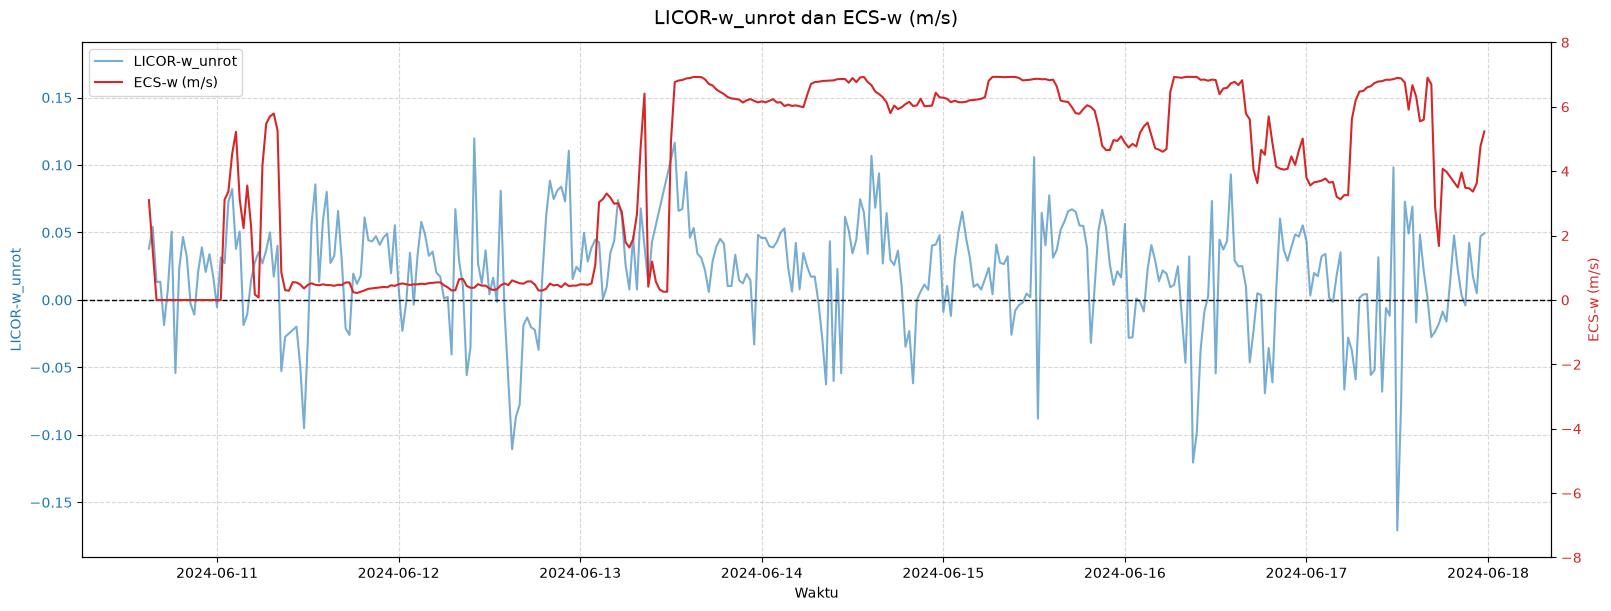

In [16]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(16,6), constrained_layout=True)

# --- LICOR (kiri) ---
ax1.plot(df.index, df["w_unrot"], label="LICOR-w_unrot", color="tab:blue", alpha=0.6)
ax1.set_xlabel("Waktu")
ax1.set_ylabel("LICOR-w_unrot", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

# --- ECS (kanan) ---
ax2 = ax1.twinx()
ecs = -df["w (m/s)"]  # tetap dibalik seperti graf kamu
ax2.plot(df.index, ecs, label="ECS-w (m/s)", color="tab:red", linewidth=1.5)
ax2.set_ylabel("ECS-w (m/s)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

# 1) Paksa skala ECS: -8…8 dengan step 2
ax2.set_ylim(-8, 8)
ax2.set_yticks(np.arange(-8, 9, 2))

# 2) Buat skala LICOR simetris terhadap nol + headroom agar tidak kepotong
licor = df["w_unrot"].to_numpy()
absmax = float(np.nanmax(np.abs(licor))) if licor.size else 1.0
headroom = max(0.02, 0.10 * absmax)            # minimal 0.02 biar lega
ax1.set_ylim(-(absmax + headroom), (absmax + headroom))

# Garis nol (otomatis sejajar karena kedua sumbu simetris)
ax1.axhline(0, color="black", linewidth=1, linestyle="--")

# Judul & grid
fig.suptitle("LICOR-w_unrot dan ECS-w (m/s)", fontsize=14)
ax1.grid(True, linestyle="--", alpha=0.5)

# Legend dipindah supaya tidak menutupi tick kanan
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.show()


**Visualisasi co2 mixing ratio**

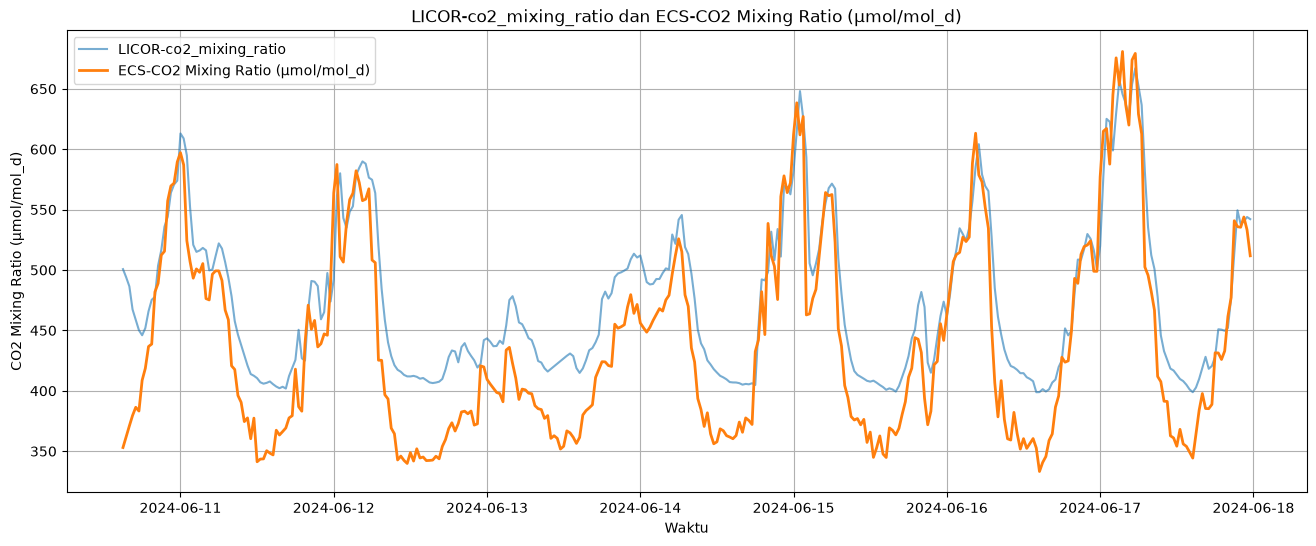

In [18]:
plt.figure(figsize=(16,6))
plt.plot(df.index, df["co2_mixing_ratio"], label="LICOR-co2_mixing_ratio", alpha=0.6)
plt.plot(df.index, df["CO2 Mixing Ratio (µmol/mol_d)"], label="ECS-CO2 Mixing Ratio (µmol/mol_d)", linewidth=2)

plt.legend()
plt.title("LICOR-co2_mixing_ratio dan ECS-CO2 Mixing Ratio (µmol/mol_d)")
plt.xlabel("Waktu")
plt.ylabel("CO2 Mixing Ratio (µmol/mol_d)")
plt.grid(True)
plt.show()

**Visualisasi Dew point temperature**

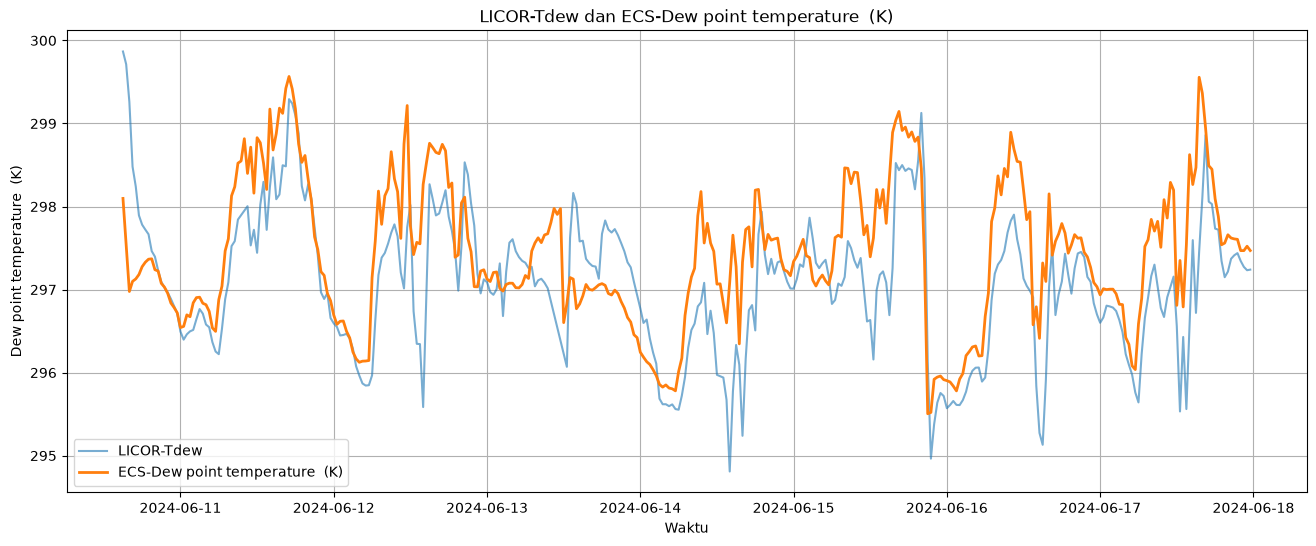

In [19]:
plt.figure(figsize=(16,6))
plt.plot(df.index, df["Tdew"], label="LICOR-Tdew", alpha=0.6)
plt.plot(df.index, df["Dew point temperature  (K)"], label="ECS-Dew point temperature  (K)", linewidth=2)

plt.legend()
plt.title("LICOR-Tdew dan ECS-Dew point temperature  (K)")
plt.xlabel("Waktu")
plt.ylabel("Dew point temperature  (K)")
plt.grid(True)
plt.show()

**Visualisasi Saturation Vapor Pressure**

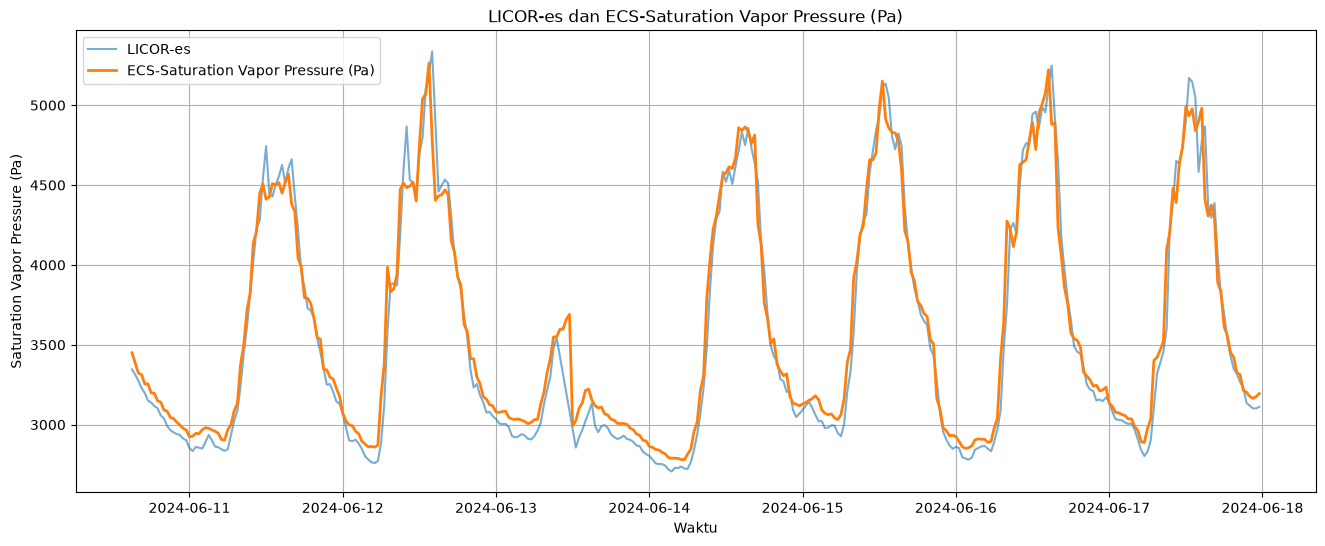

In [20]:
plt.figure(figsize=(16,6))
plt.plot(df.index, df["es"], label="LICOR-es", alpha=0.6)
plt.plot(df.index, df["Saturation Vapor Pressure (Pa)"], label="ECS-Saturation Vapor Pressure (Pa)", linewidth=2)

plt.legend()
plt.title("LICOR-es dan ECS-Saturation Vapor Pressure (Pa)")
plt.xlabel("Waktu")
plt.ylabel("Saturation Vapor Pressure (Pa)")
plt.grid(True)
plt.show()

**Visualisasi Water Vapor Partial Pressure**

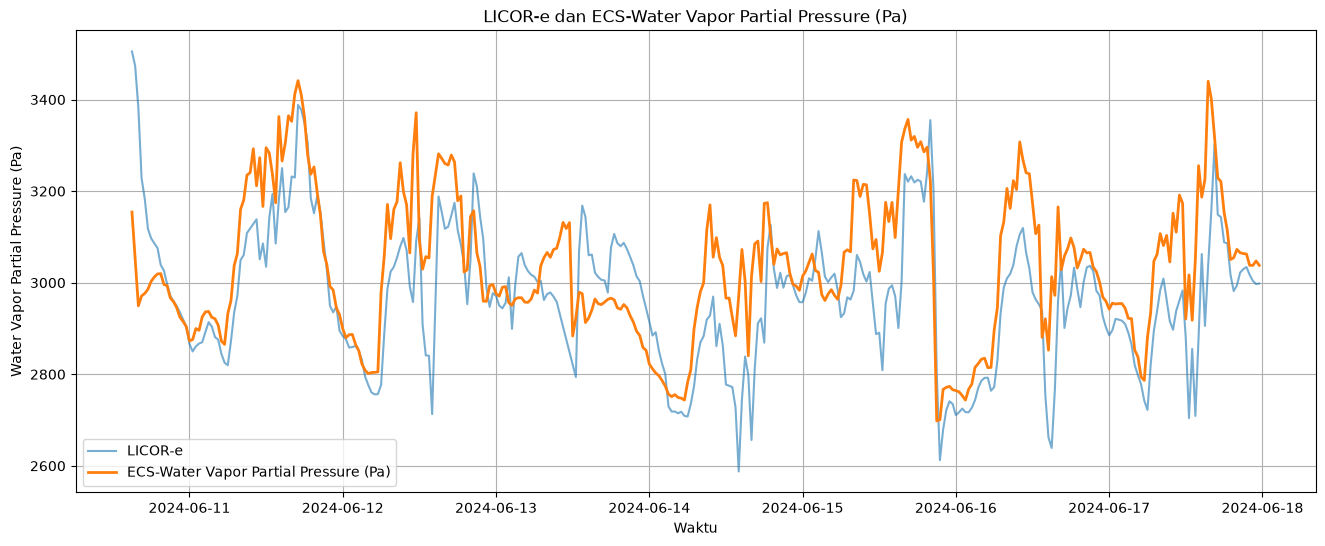

In [21]:
plt.figure(figsize=(16,6))
plt.plot(df.index, df["e"], label="LICOR-e", alpha=0.6)
plt.plot(df.index, df["Water Vapor Partial Pressure (Pa)"], label="ECS-Water Vapor Partial Pressure (Pa)", linewidth=2)

plt.legend()
plt.title("LICOR-e dan ECS-Water Vapor Partial Pressure (Pa)")
plt.xlabel("Waktu")
plt.ylabel("Water Vapor Partial Pressure (Pa)")
plt.grid(True)
plt.show()

**Visualisasi Molar Volume of Air**

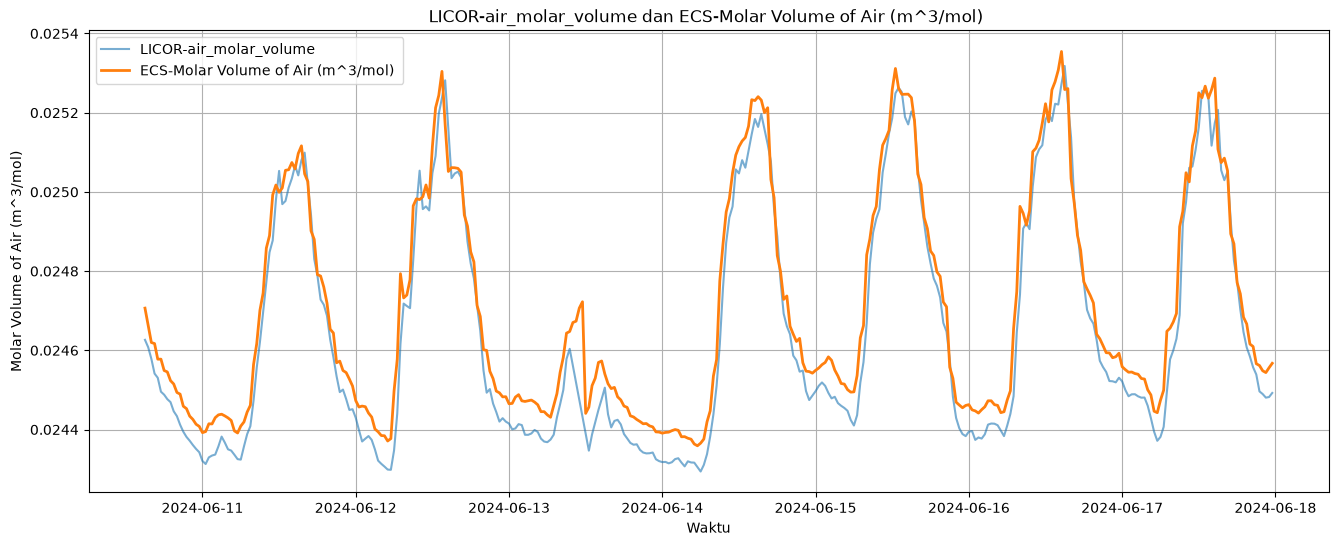

In [22]:
plt.figure(figsize=(16,6))
plt.plot(df.index, df["air_molar_volume"], label="LICOR-air_molar_volume", alpha=0.6)
plt.plot(df.index, df["Molar Volume of Air (m^3/mol)"], label="ECS-Molar Volume of Air (m^3/mol) ", linewidth=2)

plt.legend()
plt.title("LICOR-air_molar_volume dan ECS-Molar Volume of Air (m^3/mol) ")
plt.xlabel("Waktu")
plt.ylabel("Molar Volume of Air (m^3/mol)")
plt.grid(True)
plt.show()

**Visualisasi Mass Density of Air**

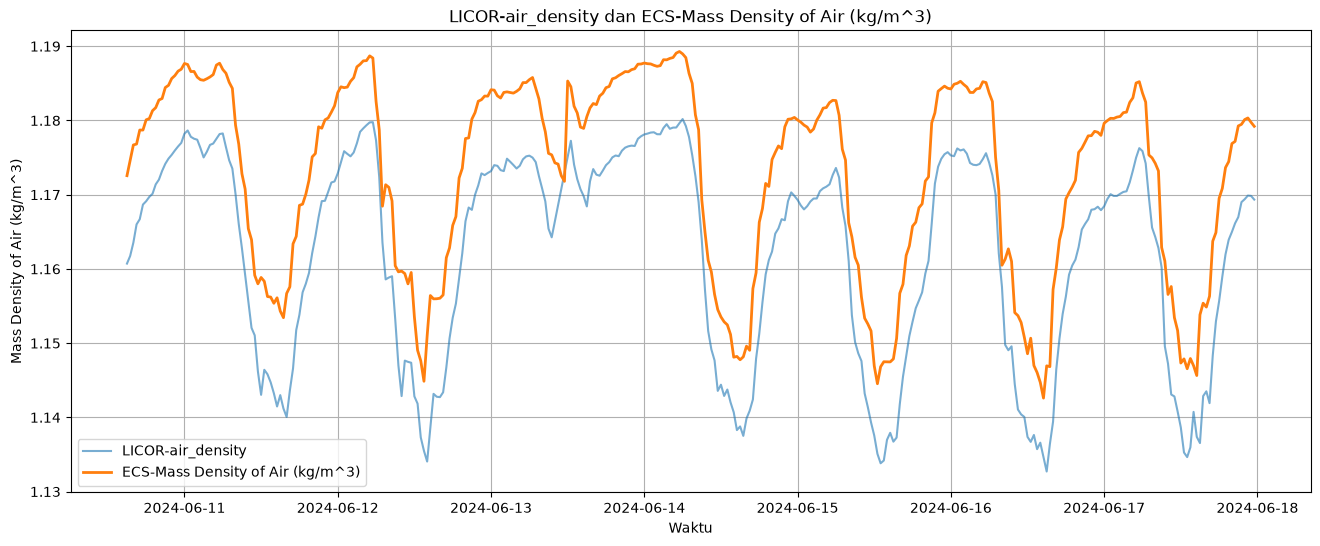

In [23]:
plt.figure(figsize=(16,6))
plt.plot(df.index, df["air_density"], label="LICOR-air_density", alpha=0.6)
plt.plot(df.index, df["Mass Density of Air (kg/m^3)"], label="ECS-Mass Density of Air (kg/m^3)", linewidth=2)

plt.legend()
plt.title("LICOR-air_density dan ECS-Mass Density of Air (kg/m^3)")
plt.xlabel("Waktu")
plt.ylabel("Mass Density of Air (kg/m^3)")
plt.grid(True)
plt.show()

**Visualisasi H2O mixing ratio**

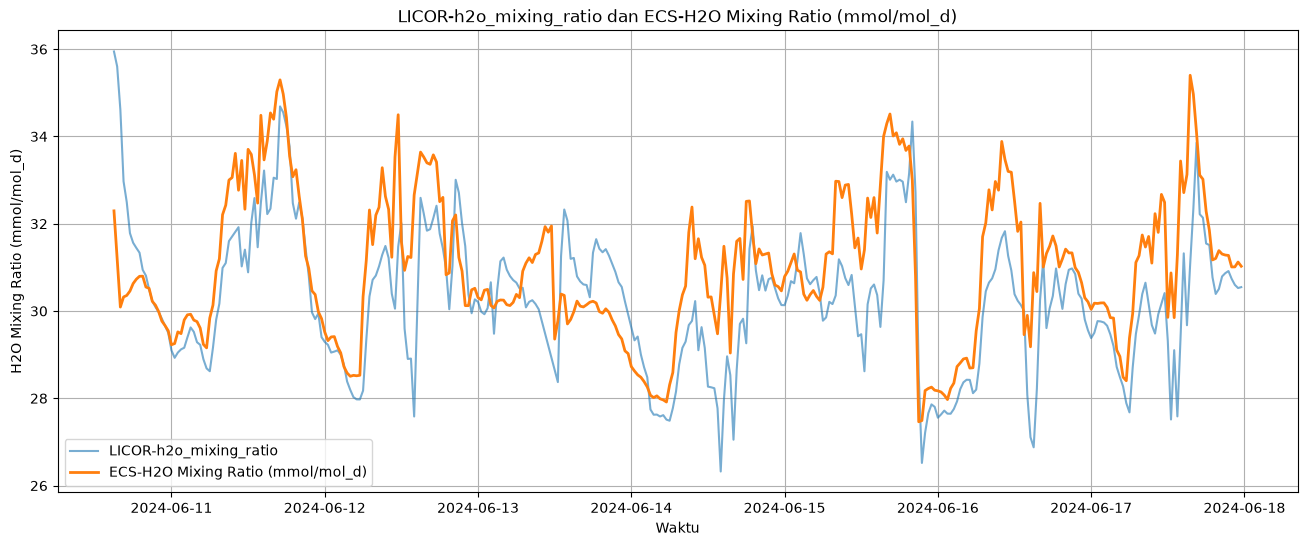

In [24]:
plt.figure(figsize=(16,6))
plt.plot(df.index, df["h2o_mixing_ratio"], label="LICOR-h2o_mixing_ratio", alpha=0.6)
plt.plot(df.index, df["H2O Mixing Ratio (mmol/mol_d)"], label="ECS-H2O Mixing Ratio (mmol/mol_d)", linewidth=2)

plt.legend()
plt.title("LICOR-h2o_mixing_ratio dan ECS-H2O Mixing Ratio (mmol/mol_d)")
plt.xlabel("Waktu")
plt.ylabel("H2O Mixing Ratio (mmol/mol_d)")
plt.grid(True)
plt.show()

**Visualisasi H2O Mole Fraction**

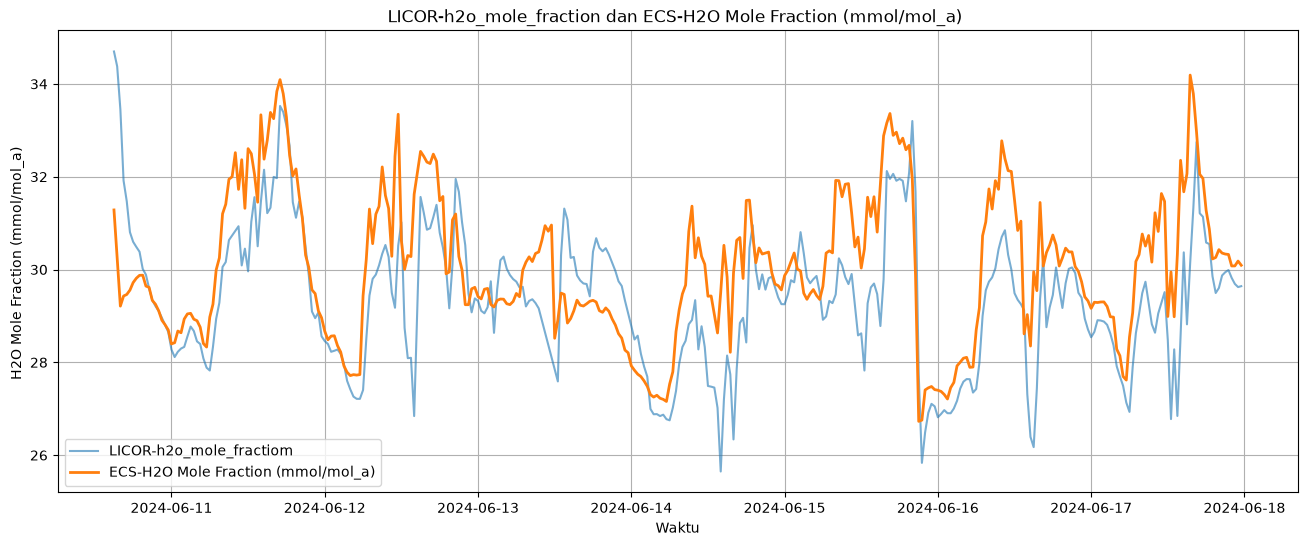

In [25]:
plt.figure(figsize=(16,6))
plt.plot(df.index, df["h2o_mole_fraction"], label="LICOR-h2o_mole_fractiom", alpha=0.6)
plt.plot(df.index, df["H2O Mole Fraction (mmol/mol_a)"], label="ECS-H2O Mole Fraction (mmol/mol_a)", linewidth=2)

plt.legend()
plt.title("LICOR-h2o_mole_fraction dan ECS-H2O Mole Fraction (mmol/mol_a) ")
plt.xlabel("Waktu")
plt.ylabel("H2O Mole Fraction (mmol/mol_a) ")
plt.grid(True)
plt.show()

**Visualisasi Fluks CO2**

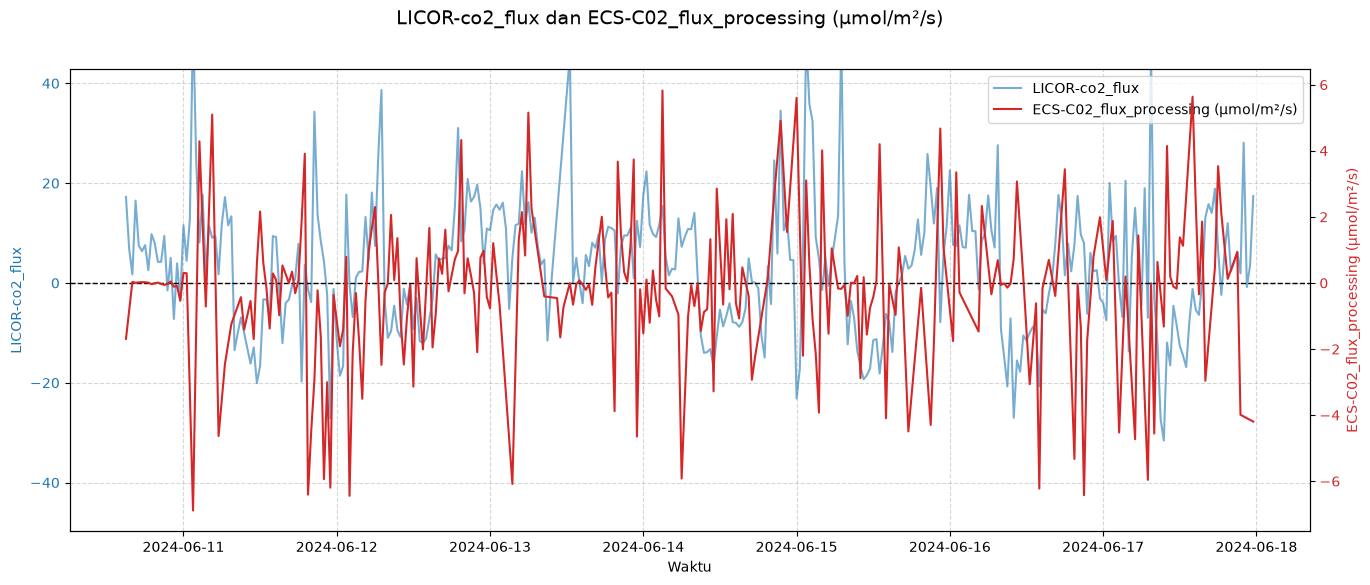

In [26]:
# Fungsi bantu: samakan posisi nol
def align_yaxis_zero(ax1, ax2):
    y1_min, y1_max = ax1.get_ylim()
    y2_min, y2_max = ax2.get_ylim()

    # proporsi posisi nol di masing-masing axis
    y1_range = y1_max - y1_min
    y2_range = y2_max - y2_min

    y1_zero = -y1_min / y1_range
    y2_zero = -y2_min / y2_range

    # cari pergeseran
    shift = y1_zero - y2_zero

    if shift > 0:
        # geser axis2
        new_min = y2_min - shift * y2_range
        new_max = y2_max - shift * y2_range
        ax2.set_ylim(new_min, new_max)
    else:
        # geser axis1
        new_min = y1_min + shift * y1_range
        new_max = y1_max + shift * y1_range
        ax1.set_ylim(new_min, new_max)


# Plot dengan double y-axis
fig, ax1 = plt.subplots(figsize=(16,6))

ax1.plot(df.index, df["co2_flux"], label="LICOR-co2_flux", color="tab:blue", alpha=0.6)
ax1.set_xlabel("Waktu")
ax1.set_ylabel("LICOR-co2_flux", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(df.index, -df["C02_flux_processing (μmol/m²/s)"], label="ECS-C02_flux_processing (μmol/m²/s)", color="tab:red", linewidth=1.5)
ax2.set_ylabel("ECS-C02_flux_processing (μmol/m²/s)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

fig.suptitle("LICOR-co2_flux dan ECS-C02_flux_processing (μmol/m²/s)", fontsize=14)
ax1.grid(True, linestyle="--", alpha=0.5)

# Samakan posisi nol
align_yaxis_zero(ax1, ax2)

# Tambah garis nol biar lebih jelas
ax1.axhline(0, color="black", linewidth=1, linestyle="--")

# Legend gabungan
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.show()

# Perbandingan Data

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 354 entries, 2024-06-10 15:00:00 to 2024-06-17 23:30:00
Data columns (total 20 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   co2_flux                           354 non-null    float64
 1   C02_flux_processing (μmol/m²/s)    354 non-null    float64
 2   h2o_mole_fraction                  354 non-null    float64
 3   H2O Mole Fraction (mmol/mol_a)     354 non-null    float64
 4   h2o_mixing_ratio                   354 non-null    float64
 5   H2O Mixing Ratio (mmol/mol_d)      354 non-null    float64
 6   air_density                        354 non-null    float64
 7   Mass Density of Air (kg/m^3)       354 non-null    float64
 8   air_molar_volume                   354 non-null    float64
 9   Molar Volume of Air (m^3/mol)      354 non-null    float64
 10  e                                  354 non-null    float64
 11  Water Vapor Partial P

- **Regresi Linear RMA (Reduced Major Axis)**

H2O Mole Fraction (mmol/mol_a)

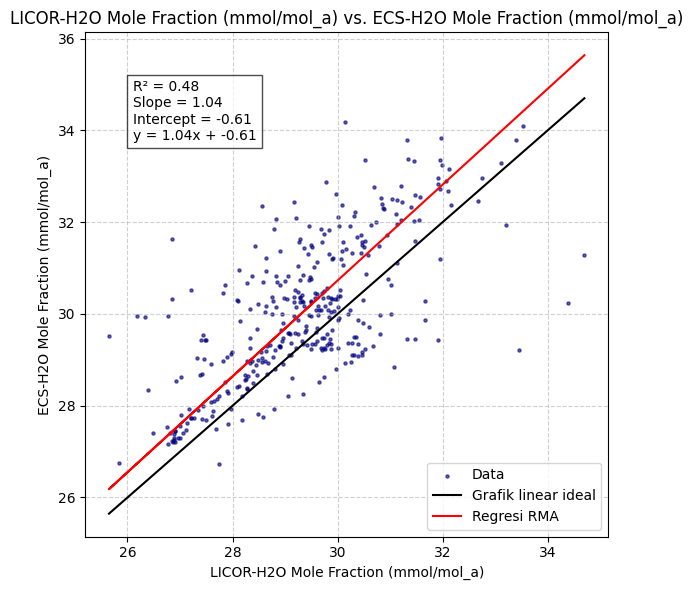

In [ ]:
x = df['h2o_mole_fraction'].values
y = df['H2O Mole Fraction (mmol/mol_a)'].values


# --- Reduced Major Axis Regression (RMA) ---
results = regress2(x, y, _method_type_2="reduced major axis")

slope = results['slope']
intercept = results['intercept']
r2 = results['r']**2

# --- Prediksi dari RMA ---
y_pred = slope * x + intercept

# --- Plotting ---
plt.figure(figsize=(6,6))
plt.scatter(x, y, s=5, color="navy", alpha=0.6, label="Data")


min_val, max_val = min(x.min(), y.min()), max(x.max(), y.max())
plt.plot([min_val, max_val], [min_val, max_val], "k-", label="Grafik linear ideal")

# RMA line
plt.plot(x, y_pred, "r-", label="Regresi RMA")


equation_text = f"R² = {r2:.2f}\nSlope = {slope:.2f}\nIntercept = {intercept:.2f}\n"
equation_text += f"y = {slope:.2f}x + {intercept:.2f}"

plt.text(min_val + (max_val-min_val)*0.05,
         max_val - (max_val-min_val)*0.1,
         equation_text, fontsize=10,
         bbox=dict(facecolor='white', alpha=0.7))

# Label & Title
plt.xlabel("LICOR-H2O Mole Fraction (mmol/mol_a)")
plt.ylabel("ECS-H2O Mole Fraction (mmol/mol_a)")
plt.title("LICOR-H2O Mole Fraction (mmol/mol_a) vs. ECS-H2O Mole Fraction (mmol/mol_a)")

# Legend in bottom right
plt.legend(loc="lower right")

plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Dew point temperature  (K)

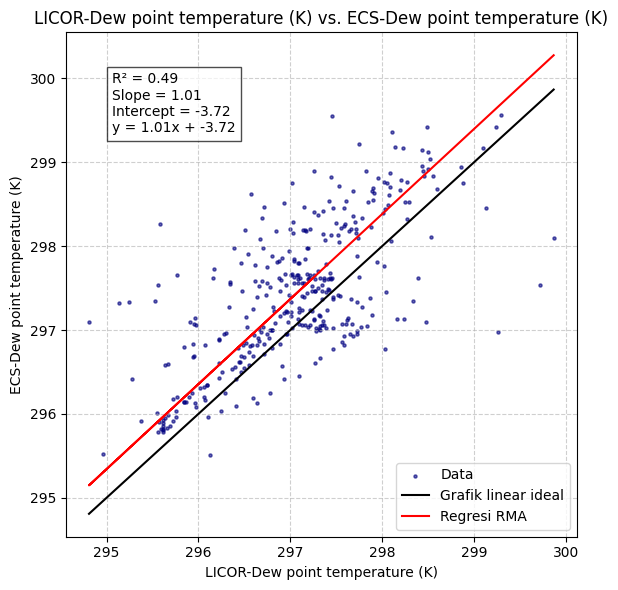

In [ ]:
x = df['Tdew'].values
y = df['Dew point temperature  (K)'].values


# --- Reduced Major Axis Regression (RMA) ---
results = regress2(x, y, _method_type_2="reduced major axis")

slope = results['slope']
intercept = results['intercept']
r2 = results['r']**2

# --- Prediksi dari RMA ---
y_pred = slope * x + intercept

# --- Plotting ---
plt.figure(figsize=(6,6))
plt.scatter(x, y, s=5, color="navy", alpha=0.6, label="Data")


min_val, max_val = min(x.min(), y.min()), max(x.max(), y.max())
plt.plot([min_val, max_val], [min_val, max_val], "k-", label="Grafik linear ideal")

# RMA line
plt.plot(x, y_pred, "r-", label="Regresi RMA")


equation_text = f"R² = {r2:.2f}\nSlope = {slope:.2f}\nIntercept = {intercept:.2f}\n"
equation_text += f"y = {slope:.2f}x + {intercept:.2f}"

plt.text(min_val + (max_val-min_val)*0.05,
         max_val - (max_val-min_val)*0.1,
         equation_text, fontsize=10,
         bbox=dict(facecolor='white', alpha=0.7))

# Label & Title
plt.xlabel("LICOR-Dew point temperature (K)")
plt.ylabel("ECS-Dew point temperature (K)")
plt.title("LICOR-Dew point temperature (K) vs. ECS-Dew point temperature (K)")

# Legend in bottom right
plt.legend(loc="lower right")

plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

H2O Mixing Ratio (mmol/mol_d)

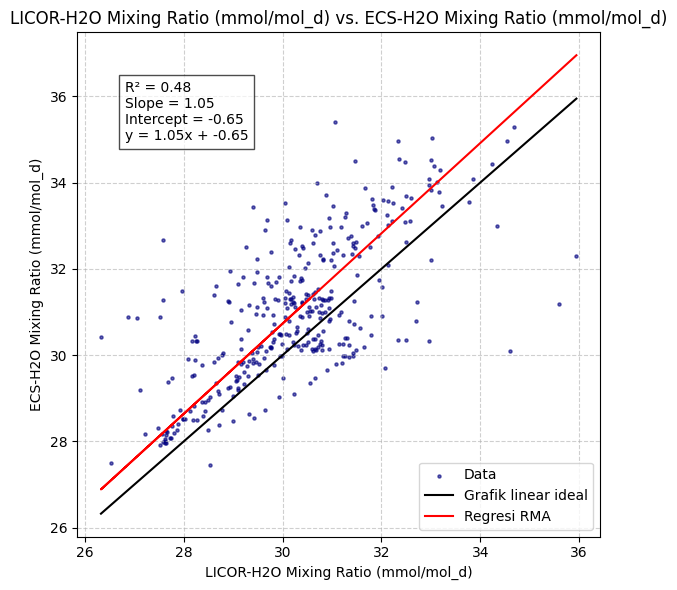

In [ ]:
x = df['h2o_mixing_ratio'].values
y = df['H2O Mixing Ratio (mmol/mol_d)'].values


# --- Reduced Major Axis Regression (RMA) ---
results = regress2(x, y, _method_type_2="reduced major axis")

slope = results['slope']
intercept = results['intercept']
r2 = results['r']**2

# --- Prediksi dari RMA ---
y_pred = slope * x + intercept

# --- Plotting ---
plt.figure(figsize=(6,6))
plt.scatter(x, y, s=5, color="navy", alpha=0.6, label="Data")


min_val, max_val = min(x.min(), y.min()), max(x.max(), y.max())
plt.plot([min_val, max_val], [min_val, max_val], "k-", label="Grafik linear ideal")

# RMA line
plt.plot(x, y_pred, "r-", label="Regresi RMA")


equation_text = f"R² = {r2:.2f}\nSlope = {slope:.2f}\nIntercept = {intercept:.2f}\n"
equation_text += f"y = {slope:.2f}x + {intercept:.2f}"

plt.text(min_val + (max_val-min_val)*0.05,
         max_val - (max_val-min_val)*0.1,
         equation_text, fontsize=10,
         bbox=dict(facecolor='white', alpha=0.7))

# Label & Title
plt.xlabel("LICOR-H2O Mixing Ratio (mmol/mol_d)")
plt.ylabel("ECS-H2O Mixing Ratio (mmol/mol_d)")
plt.title("LICOR-H2O Mixing Ratio (mmol/mol_d) vs. ECS-H2O Mixing Ratio (mmol/mol_d)")

# Legend in bottom right
plt.legend(loc="lower right")

plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Mass Density of Air (kg/m^3)

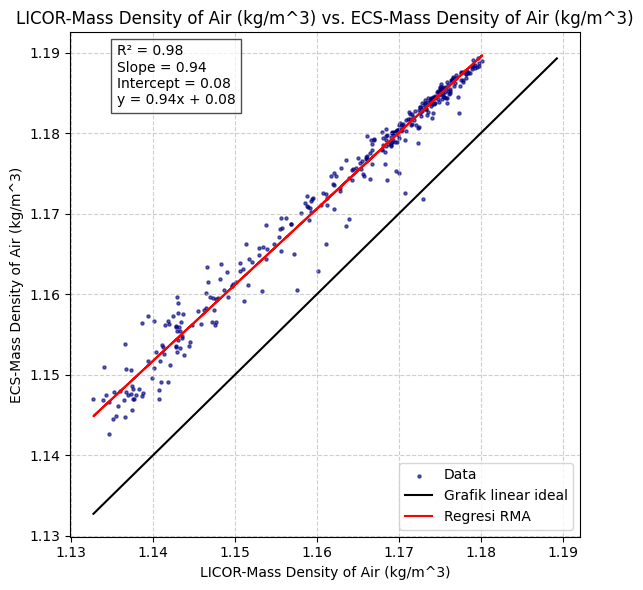

In [ ]:
x = df['air_density'].values
y = df['Mass Density of Air (kg/m^3)'].values


# --- Reduced Major Axis Regression (RMA) ---
results = regress2(x, y, _method_type_2="reduced major axis")

slope = results['slope']
intercept = results['intercept']
r2 = results['r']**2

# --- Prediksi dari RMA ---
y_pred = slope * x + intercept

# --- Plotting ---
plt.figure(figsize=(6,6))
plt.scatter(x, y, s=5, color="navy", alpha=0.6, label="Data")


min_val, max_val = min(x.min(), y.min()), max(x.max(), y.max())
plt.plot([min_val, max_val], [min_val, max_val], "k-", label="Grafik linear ideal")

# RMA line
plt.plot(x, y_pred, "r-", label="Regresi RMA")


equation_text = f"R² = {r2:.2f}\nSlope = {slope:.2f}\nIntercept = {intercept:.2f}\n"
equation_text += f"y = {slope:.2f}x + {intercept:.2f}"

plt.text(min_val + (max_val-min_val)*0.05,
         max_val - (max_val-min_val)*0.1,
         equation_text, fontsize=10,
         bbox=dict(facecolor='white', alpha=0.7))

# Label & Title
plt.xlabel("LICOR-Mass Density of Air (kg/m^3)")
plt.ylabel("ECS-Mass Density of Air (kg/m^3)")
plt.title("LICOR-Mass Density of Air (kg/m^3) vs. ECS-Mass Density of Air (kg/m^3)")

# Legend in bottom right
plt.legend(loc="lower right")

plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Molar Volume of Air (m^3/mol)

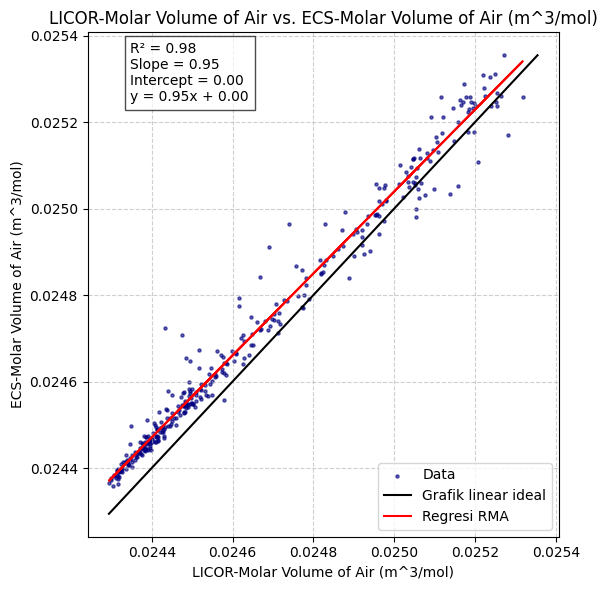

In [ ]:
x = df['air_molar_volume'].values
y = df['Molar Volume of Air (m^3/mol)'].values


# --- Reduced Major Axis Regression (RMA) ---
results = regress2(x, y, _method_type_2="reduced major axis")

slope = results['slope']
intercept = results['intercept']
r2 = results['r']**2

# --- Prediksi dari RMA ---
y_pred = slope * x + intercept

# --- Plotting ---
plt.figure(figsize=(6,6))
plt.scatter(x, y, s=5, color="navy", alpha=0.6, label="Data")


min_val, max_val = min(x.min(), y.min()), max(x.max(), y.max())
plt.plot([min_val, max_val], [min_val, max_val], "k-", label="Grafik linear ideal")

# RMA line
plt.plot(x, y_pred, "r-", label="Regresi RMA")


equation_text = f"R² = {r2:.2f}\nSlope = {slope:.2f}\nIntercept = {intercept:.2f}\n"
equation_text += f"y = {slope:.2f}x + {intercept:.2f}"

plt.text(min_val + (max_val-min_val)*0.05,
         max_val - (max_val-min_val)*0.1,
         equation_text, fontsize=10,
         bbox=dict(facecolor='white', alpha=0.7))

# Label & Title
plt.xlabel("LICOR-Molar Volume of Air (m^3/mol)")
plt.ylabel("ECS-Molar Volume of Air (m^3/mol)")
plt.title("LICOR-Molar Volume of Air vs. ECS-Molar Volume of Air (m^3/mol)")

# Legend in bottom right
plt.legend(loc="lower right")

plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

 Water Vapor Partial Pressure (Pa)

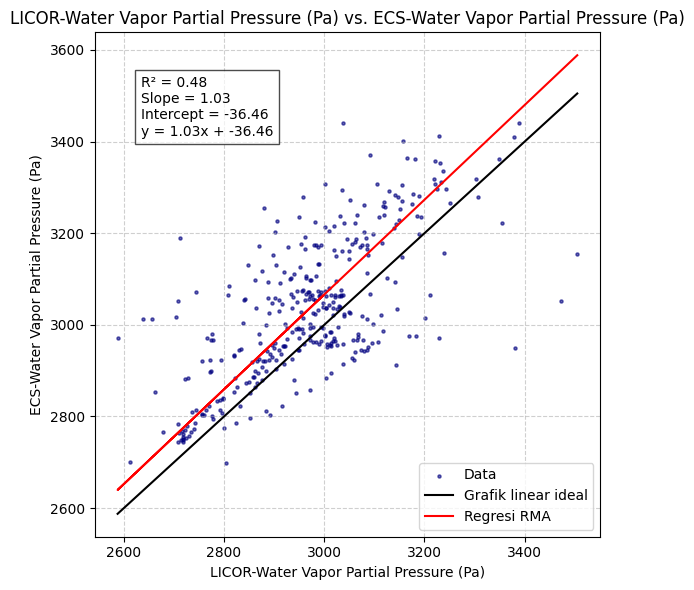

In [ ]:
x = df['e'].values
y = df['Water Vapor Partial Pressure (Pa)'].values


# --- Reduced Major Axis Regression (RMA) ---
results = regress2(x, y, _method_type_2="reduced major axis")

slope = results['slope']
intercept = results['intercept']
r2 = results['r']**2

# --- Prediksi dari RMA ---
y_pred = slope * x + intercept

# --- Plotting ---
plt.figure(figsize=(6,6))
plt.scatter(x, y, s=5, color="navy", alpha=0.6, label="Data")


min_val, max_val = min(x.min(), y.min()), max(x.max(), y.max())
plt.plot([min_val, max_val], [min_val, max_val], "k-", label="Grafik linear ideal")

# RMA line
plt.plot(x, y_pred, "r-", label="Regresi RMA")


equation_text = f"R² = {r2:.2f}\nSlope = {slope:.2f}\nIntercept = {intercept:.2f}\n"
equation_text += f"y = {slope:.2f}x + {intercept:.2f}"

plt.text(min_val + (max_val-min_val)*0.05,
         max_val - (max_val-min_val)*0.1,
         equation_text, fontsize=10,
         bbox=dict(facecolor='white', alpha=0.7))

# Label & Title
plt.xlabel("LICOR-Water Vapor Partial Pressure (Pa)")
plt.ylabel("ECS-Water Vapor Partial Pressure (Pa)")
plt.title("LICOR-Water Vapor Partial Pressure (Pa) vs. ECS-Water Vapor Partial Pressure (Pa)")

# Legend in bottom right
plt.legend(loc="lower right")

plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Saturation Vapor Pressure (Pa)

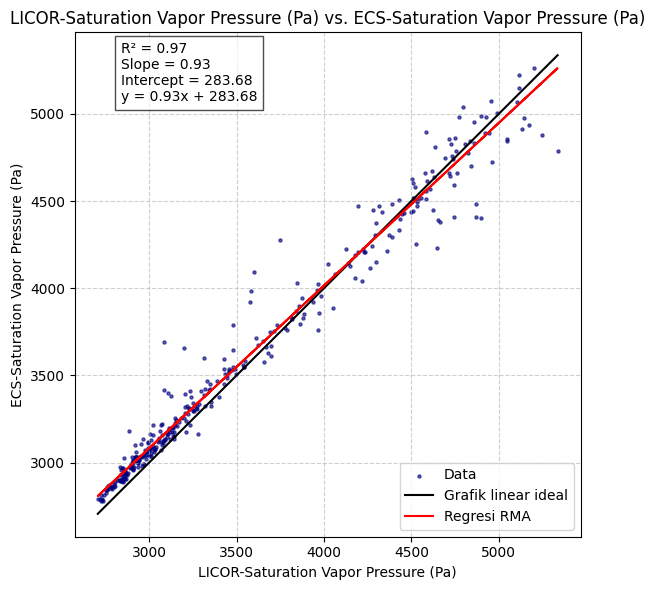

In [ ]:
x = df['es'].values
y = df['Saturation Vapor Pressure (Pa)'].values


# --- Reduced Major Axis Regression (RMA) ---
results = regress2(x, y, _method_type_2="reduced major axis")

slope = results['slope']
intercept = results['intercept']
r2 = results['r']**2

# --- Prediksi dari RMA ---
y_pred = slope * x + intercept

# --- Plotting ---
plt.figure(figsize=(6,6))
plt.scatter(x, y, s=5, color="navy", alpha=0.6, label="Data")


min_val, max_val = min(x.min(), y.min()), max(x.max(), y.max())
plt.plot([min_val, max_val], [min_val, max_val], "k-", label="Grafik linear ideal")

# RMA line
plt.plot(x, y_pred, "r-", label="Regresi RMA")


equation_text = f"R² = {r2:.2f}\nSlope = {slope:.2f}\nIntercept = {intercept:.2f}\n"
equation_text += f"y = {slope:.2f}x + {intercept:.2f}"

plt.text(min_val + (max_val-min_val)*0.05,
         max_val - (max_val-min_val)*0.1,
         equation_text, fontsize=10,
         bbox=dict(facecolor='white', alpha=0.7))

# Label & Title
plt.xlabel("LICOR-Saturation Vapor Pressure (Pa)")
plt.ylabel("ECS-Saturation Vapor Pressure (Pa)")
plt.title("LICOR-Saturation Vapor Pressure (Pa) vs. ECS-Saturation Vapor Pressure (Pa)")

# Legend in bottom right
plt.legend(loc="lower right")

plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

CO2 Mixing Ratio (µmol/mol_d)

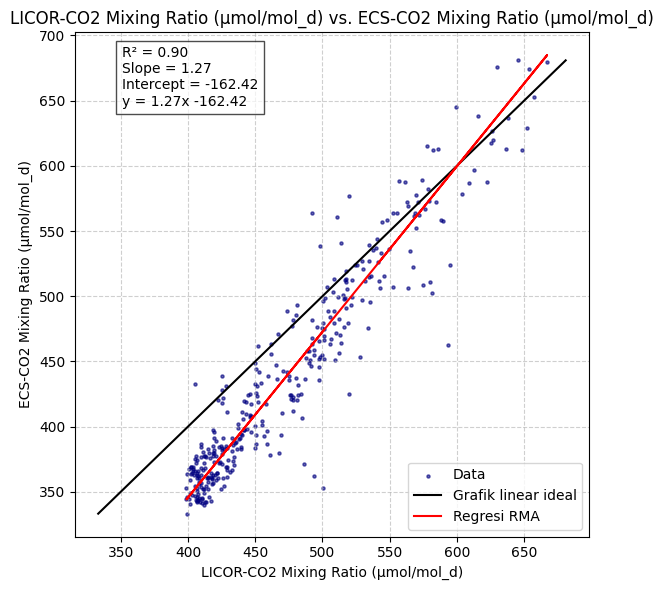

In [ ]:
x = df['co2_mixing_ratio'].values
y = df['CO2 Mixing Ratio (µmol/mol_d)'].values


# --- Reduced Major Axis Regression (RMA) ---
results = regress2(x, y, _method_type_2="reduced major axis")

slope = results['slope']
intercept = results['intercept']
r2 = results['r']**2

# --- Prediksi dari RMA ---
y_pred = slope * x + intercept

# --- Plotting ---
plt.figure(figsize=(6,6))
plt.scatter(x, y, s=5, color="navy", alpha=0.6, label="Data")


min_val, max_val = min(x.min(), y.min()), max(x.max(), y.max())
plt.plot([min_val, max_val], [min_val, max_val], "k-", label="Grafik linear ideal")

# RMA line
plt.plot(x, y_pred, "r-", label="Regresi RMA")


equation_text = f"R² = {r2:.2f}\nSlope = {slope:.2f}\nIntercept = {intercept:.2f}\n"
equation_text += f"y = {slope:.2f}x {intercept:.2f}"

plt.text(min_val + (max_val-min_val)*0.05,
         max_val - (max_val-min_val)*0.1,
         equation_text, fontsize=10,
         bbox=dict(facecolor='white', alpha=0.7))

# Label & Title
plt.xlabel("LICOR-CO2 Mixing Ratio (µmol/mol_d)")
plt.ylabel("ECS-CO2 Mixing Ratio (µmol/mol_d)")
plt.title("LICOR-CO2 Mixing Ratio (µmol/mol_d) vs. ECS-CO2 Mixing Ratio (µmol/mol_d)")

# Legend in bottom right
plt.legend(loc="lower right")

plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Angin vertikal (w)

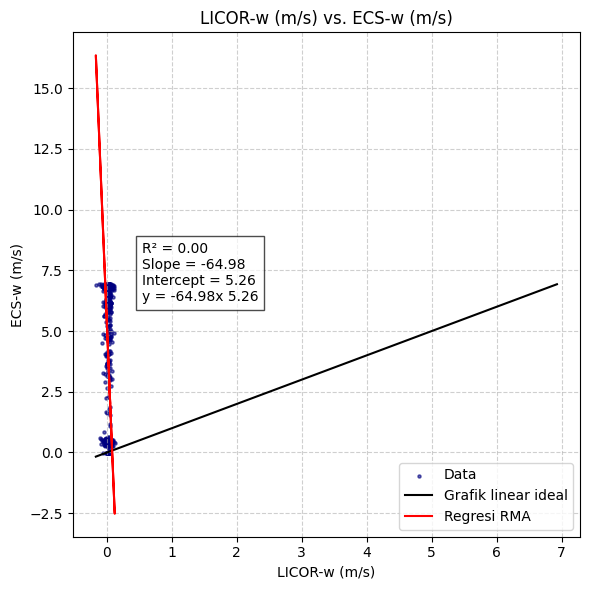

In [ ]:
x = df['w_unrot'].values
y = -df['w (m/s)'].values


# --- Reduced Major Axis Regression (RMA) ---
results = regress2(x, y, _method_type_2="reduced major axis")

slope = results['slope']
intercept = results['intercept']
r2 = results['r']**2

# --- Prediksi dari RMA ---
y_pred = slope * x + intercept

# --- Plotting ---
plt.figure(figsize=(6,6))
plt.scatter(x, y, s=5, color="navy", alpha=0.6, label="Data")


min_val, max_val = min(x.min(), y.min()), max(x.max(), y.max())
plt.plot([min_val, max_val], [min_val, max_val], "k-", label="Grafik linear ideal")

# RMA line
plt.plot(x, y_pred, "r-", label="Regresi RMA")


equation_text = f"R² = {r2:.2f}\nSlope = {slope:.2f}\nIntercept = {intercept:.2f}\n"
equation_text += f"y = {slope:.2f}x {intercept:.2f}"

plt.text(min_val + (max_val-min_val)*0.1,
         max_val - (max_val-min_val)* 0.1,
         equation_text, fontsize=10,
         bbox=dict(facecolor='white', alpha=0.7))

# Label & Title
plt.xlabel("LICOR-w (m/s)")
plt.ylabel("ECS-w (m/s)")
plt.title("LICOR-w (m/s) vs. ECS-w (m/s)")

# Legend in bottom right
plt.legend(loc="lower right")

plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

C02 flux (μmol/m²/s)

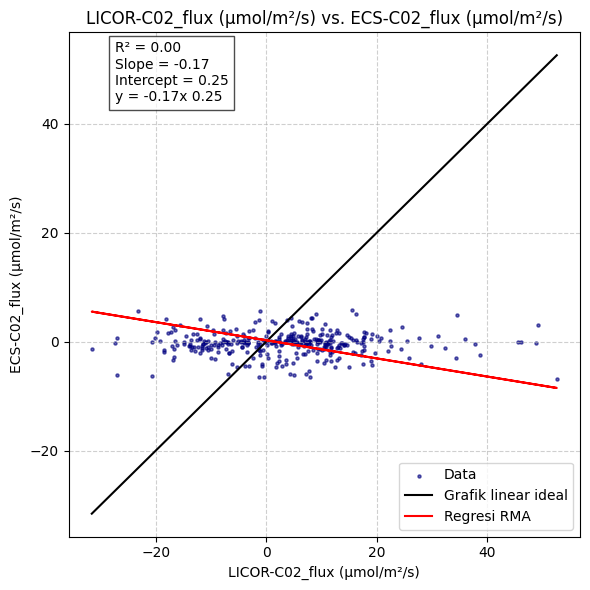

In [ ]:
x = df['co2_flux'].values
y = -df['C02_flux_processing (μmol/m²/s)'].values


# --- Reduced Major Axis Regression (RMA) ---
results = regress2(x, y, _method_type_2="reduced major axis")

slope = results['slope']
intercept = results['intercept']
r2 = results['r']**2

# --- Prediksi dari RMA ---
y_pred = slope * x + intercept

# --- Plotting ---
plt.figure(figsize=(6,6))
plt.scatter(x, y, s=5, color="navy", alpha=0.6, label="Data")


min_val, max_val = min(x.min(), y.min()), max(x.max(), y.max())
plt.plot([min_val, max_val], [min_val, max_val], "k-", label="Grafik linear ideal")

# RMA line
plt.plot(x, y_pred, "r-", label="Regresi RMA")


equation_text = f"R² = {r2:.2f}\nSlope = {slope:.2f}\nIntercept = {intercept:.2f}\n"
equation_text += f"y = {slope:.2f}x {intercept:.2f}"

plt.text(min_val + (max_val-min_val)*0.05,
         max_val - (max_val-min_val)*0.1,
         equation_text, fontsize=10,
         bbox=dict(facecolor='white', alpha=0.7))

# Label & Title
plt.xlabel("LICOR-C02_flux (μmol/m²/s)")
plt.ylabel("ECS-C02_flux (μmol/m²/s)")
plt.title("LICOR-C02_flux (μmol/m²/s) vs. ECS-C02_flux (μmol/m²/s)")

# Legend in bottom right
plt.legend(loc="lower right")

plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

- **Rerata Fluks Per Minggu**

Data μmol/m²/s

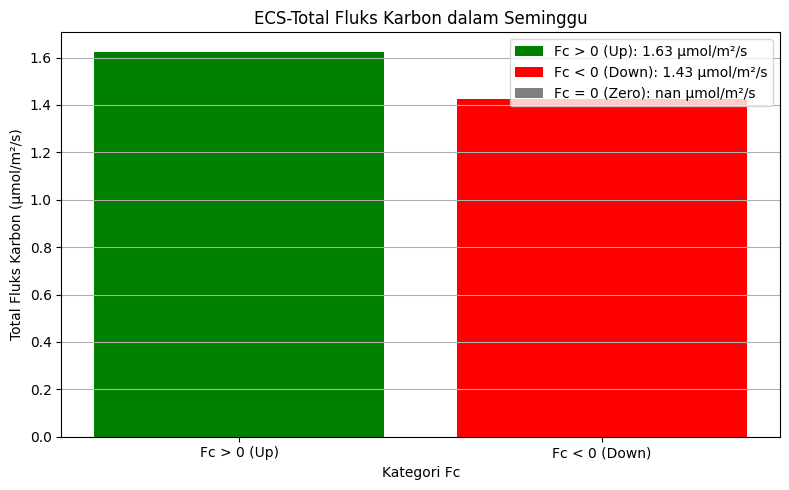

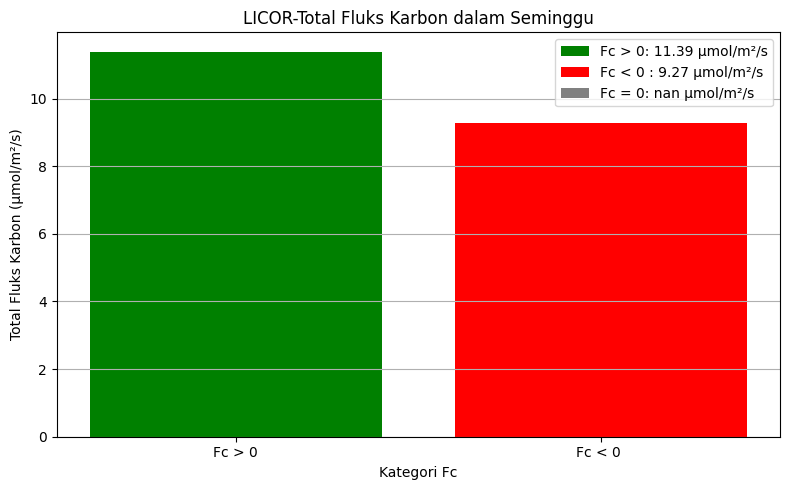

In [ ]:
# Ambil kolom Fc
Fc = df['C02_flux_processing (μmol/m²/s)']

# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = Fc[Fc > 0].mean()
Fc_neg_sum = -Fc[Fc < 0].mean()  # Ambil nilai absolut
Fc_zero_sum = Fc[Fc == 0].mean()

# Data untuk bar chart
labels = ['Fc > 0 (Up)', 'Fc < 0 (Down)', 'Fc = 0 (Zero)']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]
colors = ['green', 'red', 'gray']

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('ECS-Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


# Ambil kolom Fc
licor = df['co2_flux']


# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = licor[licor > 0].mean()
Fc_neg_sum = -licor[licor < 0].mean()
Fc_zero_sum = licor[licor == 0].mean()

# Data untuk bar chart
labels = ['Fc > 0', 'Fc < 0 ', 'Fc = 0']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('LICOR-Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

Data ton/ha/week

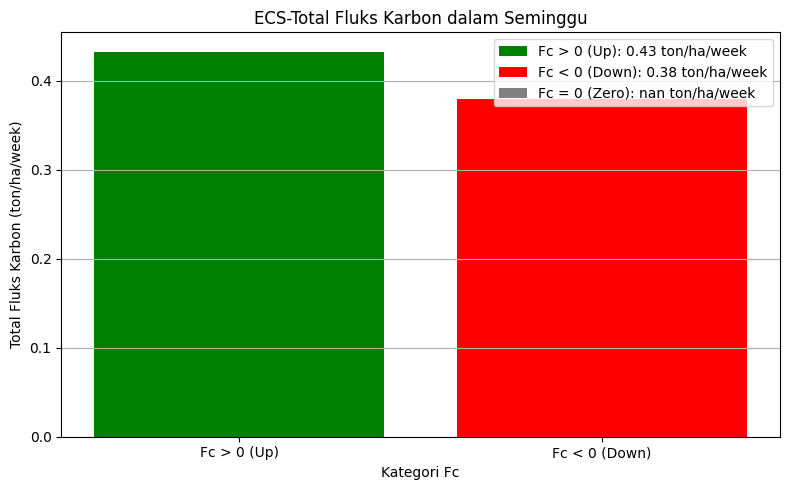

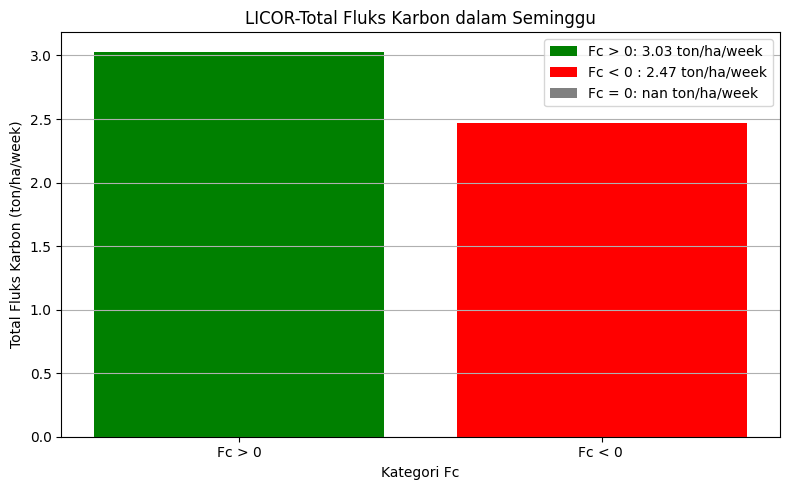

In [ ]:
# Ambil kolom Fc
Fc = df['C02_flux_processing (μmol/m²/s)'] * 44.001 * 1e-8 * 604800

# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = Fc[Fc > 0].mean()
Fc_neg_sum = -Fc[Fc < 0].mean()  # Ambil nilai absolut
Fc_zero_sum = Fc[Fc == 0].mean()

# Data untuk bar chart
labels = ['Fc > 0 (Up)', 'Fc < 0 (Down)', 'Fc = 0 (Zero)']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]
colors = ['green', 'red', 'gray']

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} ton/ha/week")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('ECS-Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (ton/ha/week)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


# Ambil kolom Fc
licor = df['co2_flux'] * 44.001 * 1e-8 * 604800


# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = licor[licor > 0].mean()
Fc_neg_sum = -licor[licor < 0].mean()
Fc_zero_sum = licor[licor == 0].mean()

# Data untuk bar chart
labels = ['Fc > 0', 'Fc < 0 ', 'Fc = 0']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} ton/ha/week")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('LICOR-Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (ton/ha/week)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()